# Replicating our paper's CIFAR-10 experiment: the starter

Our paper (Wang, Belkin and Wang, 2026, [arXiv 2602.11395](https://arxiv.org/abs/2602.11395)) steers a pretrained
diffusion model toward a class without retraining it, in two stages:
- **noise alignment (NA)** in the early, high-noise steps: the CFG recipe with two Gaussian denoisers;
- **RFM steering** in the later steps: edit the features of one block of the network along a class direction
  $v_{\mathrm{RFM}}$, then apply the CFG recipe again.

Table 2 of the paper measures both on CIFAR-10. This notebook installs the paper's code and runs every step once,
for one class: cars (CIFAR-10's "automobile", class 1), the running example from the Nov 4 slides. The replication
itself, with all ten classes and five rows of Table 2, is yours; section 5 lists it.

## Coding assignment, due Friday, November 13

First, finish your checkpoint, due this Friday, November 6. Then run this notebook on a GPU (DSMLP or Colab) and
do the replication in section 5: a table next to the paper's Table 2, sample grids, and a paragraph on what matches
and what does not. `Nov_4_assignment.pdf` has the rest of the assignment, for this week and next, and what to
submit.

**Notation, as on the slides:** $x_1$ is a clean image, $x_0$ is noise and $\sigma$ the noise level, so a noisy
image is $x = x_1 + \sigma x_0$. The paper writes the clean image as $x_0$ and the noise as $\epsilon$. Its model
works with $x_t = \sqrt{\bar\alpha_t}\, x_1 + \sqrt{1-\bar\alpha_t}\, x_0$; dividing by $\sqrt{\bar\alpha_t}$ gives
$x = x_1 + \sigma x_0$ with $\sigma = \sqrt{(1-\bar\alpha_t)/\bar\alpha_t}$, the $\sigma$ in the paper's
Appendix H.

## 0. Setup

The setup downloads:
- the paper's code, [na-rfm](https://github.com/isotrivial/na-rfm), with the
  [TFG code](https://github.com/YWolfeee/Training-Free-Guidance) it builds on, each at a fixed version;
- the CIFAR-10 diffusion model the paper uses, the U-Net of OpenAI's improved DDPM (210 MB);
- CIFAR-10, from Hugging Face (140 MB).

`run` prints a command, runs it in the code's folder, and stops the notebook if it fails.

Two lines need a fix for current library versions, and the cell makes both:
- The paper's FID script loads CIFAR-10 from Hugging Face under the dataset's old name, `cifar10`, which current
  versions of the `datasets` library reject. The fix uses the current name, `uoft-cs/cifar10`.
- TFG's FID code imports a private part of SciPy that, in SciPy 1.16, fails unless another part loads first. The
  fix adds that import.

In [1]:
import hashlib, json, os, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none: switch to a GPU runtime")
HOME = Path("/content") if Path("/content").exists() else Path.cwd()   # Colab, or the folder you start in
REPO = HOME / "na-rfm"
TFG = REPO / "baselines" / "tfg"
NARFM_COMMIT = "8e9619bc6735b03d73056bfdc13dd3659b96e127"   # the paper's public code, Oct 27, 2026
TFG_COMMIT = "f8d17f3ec2f0e7377dedf7b7bc62fad15f36cb77"     # Training-Free-Guidance, Oct 29, 2025


def run(cmd, cwd=None):
    print("$", cmd, flush=True)
    t0 = time.time()
    proc = subprocess.run(cmd, shell=True, cwd=cwd or REPO, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = [line for line in proc.stdout.splitlines() if "it/s]" not in line and "s/it]" not in line]   # no progress bars
    print("\n".join(lines[-25:]))
    if proc.returncode != 0:
        raise RuntimeError(f"failed with exit code {proc.returncode}: {cmd}")
    print(f"[{time.time() - t0:.0f} s]")


def fix(path, old, new):
    text = path.read_text()
    if new not in text:
        path.write_text(text.replace(old, new))


if not REPO.exists():
    run(f"git clone -q https://github.com/isotrivial/na-rfm.git {REPO}", cwd=HOME)
run(f"git checkout -q {NARFM_COMMIT}")
if not TFG.exists():
    run(f"git clone -q https://github.com/YWolfeee/Training-Free-Guidance.git {TFG}")
run(f"git checkout -q {TFG_COMMIT}", cwd=TFG)
run(f"{sys.executable} -m pip install -q datasets scikit-learn scipy transformers gdown")

fix(REPO / "repro" / "evaluate_saved_samples.py", 'load_dataset("cifar10")', 'load_dataset("uoft-cs/cifar10")')
sqrtm_import = "from scipy.linalg._matfuncs_sqrtm_triu import within_block_loop"
fix(TFG / "evaluations" / "utils" / "torch_sqrtm.py", sqrtm_import, "import scipy.linalg._matfuncs_sqrtm\n" + sqrtm_import)

os.chdir(REPO)
os.environ["PYTHONPATH"] = f"{REPO}:{TFG}"   # for the scripts this notebook runs
sys.path[:0] = [str(REPO), str(TFG)]         # for this notebook itself

GPU: Tesla T4
$ git clone -q https://github.com/isotrivial/na-rfm.git /content/na-rfm

[1 s]
$ git checkout -q 8e9619bc6735b03d73056bfdc13dd3659b96e127

[0 s]
$ git clone -q https://github.com/YWolfeee/Training-Free-Guidance.git /content/na-rfm/baselines/tfg

[0 s]
$ git checkout -q f8d17f3ec2f0e7377dedf7b7bc62fad15f36cb77

[0 s]
$ /usr/bin/python3 -m pip install -q datasets scikit-learn scipy transformers gdown

[3 s]


In [2]:
from google.colab import drive
drive.mount("/content/drive")
STORE = Path("/content/drive/MyDrive/dsc180_narfm")
STORE.mkdir(parents=True, exist_ok=True)

# Point the repo's output folders at Drive
for rel in ["repro/assets/cifar10_filters", "repro/assets/cifar10_concepts", "results/part4"]:
    link, target = REPO / rel, STORE / Path(rel).name
    target.mkdir(parents=True, exist_ok=True)
    link.parent.mkdir(parents=True, exist_ok=True)
    if not link.is_symlink():
        if link.exists():
            run(f"cp -rn {link}/. {target}/ && rm -rf {link}")
        link.symlink_to(target)
print("saving to", STORE)

Mounted at /content/drive
saving to /content/drive/MyDrive/dsc180_narfm


The model: na-rfm loads the checkpoint file that TFG distributes, `openai_cifar10.pt`, from TFG's shared
folder. The check below makes sure you have exactly the file the paper used. If `gdown` fails (Google Drive limits
popular files), download `openai_cifar10.pt` by hand from
[TFG's folder](https://drive.google.com/drive/folders/1fS7dKpO4O-FjaLwuRXuHBxEOlkqMMTGh) into
`na-rfm/data/checkpoints/` and run the cell again.

In [3]:
CKPT = REPO / "data" / "checkpoints" / "openai_cifar10.pt"
if not CKPT.exists():
    CKPT.parent.mkdir(parents=True, exist_ok=True)
    run(f"gdown 1eInndCjx389Tl45kfmntVo23f_-82bHl -O {CKPT}")
md5 = hashlib.md5(CKPT.read_bytes()).hexdigest()
assert md5 == "2754c3e3c778ef6e0ab98e8aacaefaf9", f"not the paper's checkpoint (md5 {md5}): delete it and download again"
print(f"checkpoint OK: {CKPT.stat().st_size / 1e6:.0f} MB")

$ gdown 1eInndCjx389Tl45kfmntVo23f_-82bHl -O /content/na-rfm/data/checkpoints/openai_cifar10.pt
Downloading...
From (original): https://drive.google.com/uc?id=1eInndCjx389Tl45kfmntVo23f_-82bHl
From (redirected): https://drive.google.com/uc?id=1eInndCjx389Tl45kfmntVo23f_-82bHl&confirm=t&uuid=47d5a9c5-9f5d-4f99-a2e9-baf03d8f8c3b
To: /content/na-rfm/data/checkpoints/openai_cifar10.pt

  0%|          | 0.00/210M [00:00<?, ?B/s]
  9%|▊         | 18.4M/210M [00:00<00:01, 182MB/s]
 20%|██        | 42.5M/210M [00:00<00:00, 213MB/s]
 32%|███▏      | 67.6M/210M [00:00<00:00, 229MB/s]
 45%|████▍     | 93.8M/210M [00:00<00:00, 233MB/s]
 56%|█████▌    | 117M/210M [00:00<00:00, 206MB/s] 
 66%|██████▌   | 139M/210M [00:00<00:00, 167MB/s]
 76%|███████▌  | 160M/210M [00:00<00:00, 177MB/s]
 88%|████████▊ | 185M/210M [00:00<00:00, 175MB/s]
 97%|█████████▋| 203M/210M [00:01<00:00, 172MB/s]
100%|██████████| 210M/210M [00:01<00:00, 153MB/s]
[3 s]
checkpoint OK: 210 MB


CIFAR-10's 50,000 training images, one folder per class (`label_0` to `label_9`), which is the layout the
paper's PCA script reads. Class 1 is the cars.

In [4]:
from datasets import load_dataset
from PIL import Image

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CAR = 1
BY_CLASS = HOME / "cifar10" / "train_by_class"
cifar = load_dataset("uoft-cs/cifar10", split="train")
assert cifar.features["label"].names == CLASSES
labels = np.array(cifar["label"])
pixels = np.stack([np.asarray(img) for img in cifar["img"]])   # 50,000 x 32 x 32 x 3, values 0 to 255
if not (BY_CLASS / "label_9").exists():
    for i, (img, y) in enumerate(zip(pixels, labels)):
        folder = BY_CLASS / f"label_{y}"
        folder.mkdir(parents=True, exist_ok=True)
        Image.fromarray(img).save(folder / f"{i:05d}.png")
print({CLASSES[k]: len(list((BY_CLASS / f"label_{k}").glob("*.png"))) for k in range(10)})

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


## 1. Noise alignment's two Gaussian denoisers

Noise alignment needs two Gaussian denoisers, one from the 5,000 training cars ($D_{\mathrm{car}}$) and one from all
50,000 training images ($D_{\mathrm{all}}$). Each keeps a mean image $\mu$ and the top $k = 1{,}000$ PCA directions
$u_k$ with their variances $\nu_k$ (the paper's Table 16), and denoises with the formula from the slides:

$$D(x;\sigma) = \mu + \sum_k \frac{\nu_k}{\nu_k + \sigma^2}\, \langle x - \mu,\, u_k\rangle\, u_k .$$

`pca/build_filters.py` computes $\mu$, $u_k$ and $\nu_k$, and saves them as `class_1.pt` and `full_dataset.pt`.

$D_{\mathrm{all}}$ must see every class, so it is built with `--num-images 0`, which means all 50,000 images. With
`--full-dataset`, the script keeps the first N files in folder order, so N = 5,000 would be airplanes only.

This cell takes a few minutes, mostly for the PCA of all 50,000 images.

In [5]:
FILTERS = REPO / "repro" / "assets" / "cifar10_filters"
build = (f"{sys.executable} pca/build_filters.py --image-root {BY_CLASS} --output-dir {FILTERS} "
         f"--image-size 32 --components 1000 --backend cpu")
if not (FILTERS / "full_dataset.pt").exists():
    run(f"{build} --full-dataset --num-images 0")          # D_all: all 50,000 training images
if not (FILTERS / f"class_{CAR}.pt").exists():
    run(f"{build} --classes {CAR} --num-images 5000")      # D_car: the 5,000 training cars

$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --full-dataset --num-images 0
Using PCA backend: cpu

[497 s]
$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --classes 1 --num-images 5000
Using PCA backend: cpu

[47 s]


What the two Gaussian denoisers keep: the mean image and the first PCA directions, for cars and for all
images. Grey is zero; a direction is added to or subtracted from the mean.

cars: 5000 images, 1000 directions
all images: 50000 images, 1000 directions


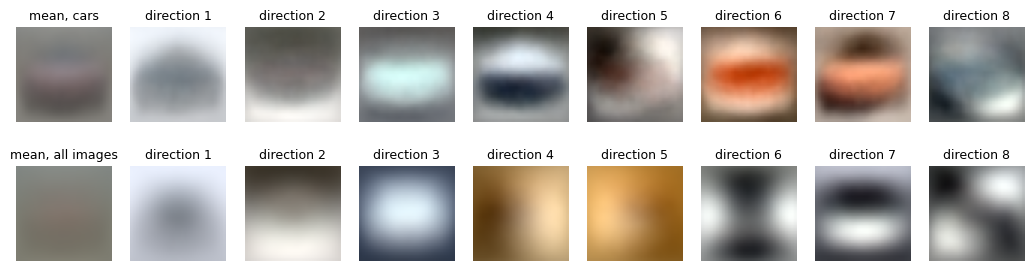

In [6]:
def as_image(v):
    return np.clip(v.reshape(3, 32, 32).transpose(1, 2, 0) / 2 + 0.5, 0, 1)   # [-1, 1] -> [0, 1]


def as_direction(u):
    u = u.reshape(3, 32, 32).transpose(1, 2, 0)
    return np.clip(0.5 + 0.5 * u / np.abs(u).max(), 0, 1)


fig, axes = plt.subplots(2, 9, figsize=(13, 3.3))
for row, (name, file) in enumerate([("cars", f"class_{CAR}.pt"), ("all images", "full_dataset.pt")]):
    f = torch.load(FILTERS / file, weights_only=False)
    axes[row, 0].imshow(as_image(f["mean_patch"].numpy()))
    axes[row, 0].set_title(f"mean, {name}", fontsize=9)
    for k in range(8):
        axes[row, k + 1].imshow(as_direction(f["eigenvectors"][:, k].numpy()))
        axes[row, k + 1].set_title(f"direction {k + 1}", fontsize=9)
    print(f"{name}: {f['num_images']} images, {f['eigenvectors'].shape[1]} directions")
for ax in axes.flat:
    ax.axis("off")
plt.show()

## 2. The RFM direction for cars

RFM steering edits the features $h$ of one block of the network: input block 9, with 256 numbers at each of
8 × 8 positions, 16,384 in all. To find the car direction $v_{\mathrm{RFM}}$, the paper (Table 16):
1. takes 1,000 training images of each class and adds a little noise, $\sigma \approx 0.21$, which is the model's
   step $t = 60$;
2. records $h$ for each image;
3. fits an RFM classifier, cars against the other nine classes, with a Laplace kernel, bandwidth 100,
   regularization $10^{-3}$ and 5 iterations;
4. combines the top three eigenvectors of what RFM learned into $v_{\mathrm{RFM}}$.

The classifier is checked on 20% of the images it did not see; AUC is the probability that it scores a random car
above a random non-car.

In [7]:
from torch.utils.data import DataLoader, TensorDataset

from na_rfm.activation_collection import collect_activations
from na_rfm.model_loaders import load_openai_unet
from na_rfm.rfm_training import RFMTrainConfig, get_direction, train_binary_rfm

SIGMA = 0.21
first = np.concatenate([np.flatnonzero(labels == k)[:1000] for k in range(10)])   # the first 1,000 of each class
images = torch.from_numpy(pixels[first]).permute(0, 3, 1, 2).float() / 127.5 - 1   # in [-1, 1]
loader = DataLoader(TensorDataset(images, torch.from_numpy(labels[first])), batch_size=250)

unet = load_openai_unet(str(CKPT), image_size=32, device="cuda")
torch.manual_seed(0)
H, H_labels = collect_activations(unet, loader, block_name="input_blocks_9",
                                  alpha_prod_t=1 / (1 + SIGMA**2), timestep=60, device="cuda")
print("features h:", tuple(H.shape))
del unet
torch.cuda.empty_cache()

features h: (10000, 16384)


In [8]:
CONCEPTS = REPO / "repro" / "assets" / "cifar10_concepts"
CONCEPTS.mkdir(parents=True, exist_ok=True)

t0 = time.time()
config = RFMTrainConfig(bandwidth=100.0, reg=1e-3, n_iters=5, top_k=3, device="cuda")
result = train_binary_rfm(H, H_labels, target_value=CAR, config=config)
v_rfm = get_direction(result, topk=3).cpu()
torch.save({"direction": v_rfm, "eigenvectors": result.eigenvectors.cpu(), "eigenvalues": result.eigenvalues.cpu(),
            "sign": int(result.sign), "auc": float(result.best_auc), "block_name": "input_blocks_9",
            "timestep": 60, "sigma": SIGMA}, CONCEPTS / f"class_{CAR}.pt")
print(f"cars against the rest: AUC {result.best_auc:.3f} on held-out images ({time.time() - t0:.0f} s)")

cars against the rest: AUC 0.969 on held-out images (54 s)


## 3. The paper's smoke test

`cifar10.sh` is the paper's launcher. With `MODE=smoke` it draws 4 images of one class twice: with noise
alignment only ($\lambda = 8$), and with NA-RFM. It measures accuracy with the paper's evaluator, a ConvNeXt-Tiny
classifier fine-tuned on CIFAR-10. If this cell passes, your setup works.

$ MODE=smoke TARGETS=1 bash cifar10.sh
cifar10_camera_ready_start=2026-11-13T06:36:55+0000
mode=smoke output_dir=results/camera_ready_repro targets=1
num_samples=4 seed_start=0 batch_size=64
Wrapper manifest written to: results/camera_ready_repro/_wrapper_runs/20261113_063655_283689
[1/1] running cifar10/na_only/class_1
  log: results/camera_ready_repro/_wrapper_runs/20261113_063655_283689/logs/001_cifar10_na_only_class_1.log
Completed. Wrapper logs are in: results/camera_ready_repro/_wrapper_runs/20261113_063655_283689
Wrapper manifest written to: results/camera_ready_repro/_wrapper_runs/20261113_063726_935527
[1/1] running cifar10/na_rfm/1
  log: results/camera_ready_repro/_wrapper_runs/20261113_063726_935527/logs/001_cifar10_na_rfm_1.log
Completed. Wrapper logs are in: results/camera_ready_repro/_wrapper_runs/20261113_063726_935527
cifar10_camera_ready_done=2026-11-13T06:37:45+0000
[51 s]


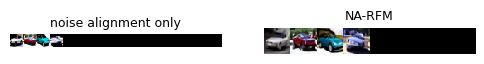

In [9]:
run(f"MODE=smoke TARGETS={CAR} bash cifar10.sh")

smoke = REPO / "results" / "camera_ready_repro" / "cifar10"
fig, axes = plt.subplots(1, 2, figsize=(6, 1.8))
for ax, (name, path) in zip(axes, [("noise alignment only", next((smoke / "na_only").glob("automobile_*.png"))),
                                   ("NA-RFM", smoke / "na_rfm" / "automobile" / "grid.png")]):
    ax.imshow(Image.open(path), interpolation="nearest")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.show()

## 4. A first measurement: 64 cars, unguided and with NA-RFM

Both rows start from the same 64 noises (seeds 0 to 63) and differ only in the steering:
- **unguided:** $\lambda = 0$ and $w_{\mathrm{RFM}} = 0$, so nothing is steered;
- **NA-RFM:** the paper's setting, which is the script's default: $\lambda = 3$ while $\sigma \ge 3.33$, then the
  edit $h \leftarrow h + w_{\mathrm{RFM}}\,\|h\|\,v_{\mathrm{RFM}}$ with $w_{\mathrm{RFM}} = 1$ and amplification
  $s = 2$ while $\sigma \in [0.01, 11.69]$.

Two numbers for each row:
- **accuracy:** the percentage of images the evaluator calls a car;
- **FID:** against all 6,000 CIFAR-10 cars, train and test.

With only 64 images FID is far higher than the paper's, because FID is biased upward when there are few
images. Compare rows only at the same number of images.

$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes 1 --num-samples 64 --batch-size 64 --output-dir /content/na-rfm/results/first/unguided --gaussian-strength 0 --rfm-strength 0
Loading CIFAR-10 diffusion model: data/checkpoints/openai_cifar10.pt

Sampling 1 (automobile)

automobile: 6/64 = 9.4%

Average accuracy: 9.4%
Results saved to: /content/na-rfm/results/first/unguided
[58 s]
$ /usr/bin/python3 repro/evaluate_saved_samples.py --dataset cifar10 --samples-root /content/na-rfm/results/first/unguided --targets 1 --output /content/na-rfm/results/first/unguided/quality.json --batch-size 64

  0%|          | 0.00/91.2M [00:00<?, ?B/s]
 10%|▉         | 9.00M/91.2M [00:00<00:00, 94.1MB/s]
 29%|██▉       | 26.8M/91.2M [00:00<00:00, 148MB/s] 
 49%|████▉     | 45.1M/91.2M [00:00<00:00, 167MB/s]
 70%|██████▉   | 63.5M/91.2M [00:00<00:00, 177MB/s]
 89%|████████▉ | 81.2M/91.2M [00:00<00:00, 180MB/s]
100%|██████████| 91.2M/91.2M [00:00<00:00, 171MB/s]
No cache path provided. Computing refer

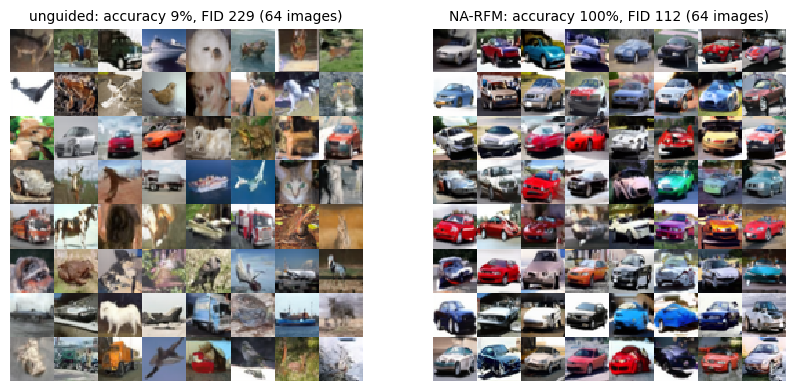

In [10]:
FIRST = REPO / "results" / "first"
ROWS = {"unguided": "--gaussian-strength 0 --rfm-strength 0", "NA-RFM": ""}
scores = {}
for name, flags in ROWS.items():
    out = FIRST / name
    run(f"{sys.executable} repro/run_cifar10_na_rfm.py --classes {CAR} --num-samples 64 --batch-size 64 "
        f"--output-dir {out} {flags}")
    run(f"{sys.executable} repro/evaluate_saved_samples.py --dataset cifar10 --samples-root {out} --targets {CAR} "
        f"--output {out / 'quality.json'} --batch-size 64")
    scores[name] = json.loads((out / "quality.json").read_text())

fig, axes = plt.subplots(1, 2, figsize=(10, 5.5))
for ax, name in zip(axes, ROWS):
    q = scores[name]
    ax.imshow(Image.open(FIRST / name / "automobile" / "grid.png"), interpolation="nearest")
    ax.set_title(f"{name}: accuracy {q['average_accuracy']:.0f}%, FID {q['average_fid']:.0f} (64 images)", fontsize=10)
    ax.axis("off")
plt.show()

Table 2 also reports sampling time, for a batch of 16 images with 100 DDIM steps on an A100. We time the
batch size the scripts use, 64. `seconds_per_image` draws two batches of 64 cars after a warm-up batch and returns
the seconds per image. Pass it the same flags as the row's script.

In [11]:
from na_rfm.ddim_sampling import build_ddim_schedule
from repro import run_cifar10_na_only as na_only
from repro.run_cifar10_na_rfm import parse_args, sample_class

unet = load_openai_unet(str(CKPT), image_size=32, device="cuda")


def seconds_per_image(flags="", na_only_strength=None, batch=64, repeats=2):
    # flags: those of run_cifar10_na_rfm.py; or na_only_strength=lambda, for run_cifar10_na_only.py --mode diff
    if na_only_strength is None:
        args = parse_args(f"--classes {CAR} --num-samples {batch} --batch-size {batch} {flags}".split())
        schedule = build_ddim_schedule(1000, args.inference_steps, 0.0001, 0.02, "cuda")
        draw = lambda: sample_class(unet=unet, schedule=schedule, class_idx=CAR, args=args)
    else:
        schedule = na_only.build_ddim_schedule(1000, 100, 0.0001, 0.02, "cuda")
        guidance = na_only.WienerGuidance(str(FILTERS / f"class_{CAR}.pt"), str(FILTERS / "full_dataset.pt"),
                                          mode="diff", strength=na_only_strength, start_step=0, end_step=50,
                                          num_components=1000, device="cuda")
        draw = lambda: na_only.sample_with_wiener_guidance(unet, schedule, guidance, batch,
                                                           na_only.StackedRandomGenerator("cuda", list(range(batch))))
    times = []
    for _ in range(repeats + 1):   # the first batch warms up the GPU
        torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            draw()
        torch.cuda.synchronize()
        times.append(time.time() - t0)
    return min(times[1:]) / batch


print(f"NA-RFM: {seconds_per_image():.2f} s per image at batch size 64 on {torch.cuda.get_device_name(0)}")
print("(the paper's Table 2: 6.2 s for a batch of 16 on an A100)")

NA-RFM: 0.67 s per image at batch size 64 on Tesla T4
(the paper's Table 2: 6.2 s for a batch of 16 on an A100)


## 5. Your turn: the replication (due Friday, November 13)

**a. The offline parts for all ten classes.**
- Build `class_k.pt` for every class: section 1's command with `--classes 0 2 3 4 5 6 7 8 9`.
- Fit an RFM direction for every class: section 2's last cell with `target_value=k`, saved as `class_k.pt`.
  Report each class's AUC.

**b. Five rows, 256 images per class**, with seeds 0 to 255 in every row and 100 DDIM steps. All settings are
in the paper's Tables 16 and 17:

| Row | Script | Noise alignment | RFM steering |
|---|---|---|---|
| Unguided (not in Table 2) | `run_cifar10_na_rfm.py` | none, $\lambda = 0$ | none, $w_{\mathrm{RFM}} = 0$ |
| Noise alignment only, $\lambda = 3$ | `run_cifar10_na_only.py --mode diff` | $\lambda = 3$ while $\sigma \ge 3.33$ (steps 0 to 50) | none |
| Noise alignment only, $\lambda = 8$ | `run_cifar10_na_only.py --mode diff` | $\lambda = 8$ while $\sigma \ge 3.33$ (steps 0 to 50) | none |
| RFM only (all steps) | `run_cifar10_na_rfm.py` | none, $\lambda = 0$ | $w_{\mathrm{RFM}} = 1$, $s = 2$, at every step |
| NA-RFM | `run_cifar10_na_rfm.py` | $\lambda = 3$ while $\sigma \ge 3.33$ | $w_{\mathrm{RFM}} = 1$, $s = 2$, while $\sigma \in [0.01, 11.69]$ |

Each script's `--help` lists its flags.
- In `run_cifar10_na_rfm.py`, `--gaussian-strength` is $\lambda$, `--rfm-strength` is $w_{\mathrm{RFM}}$,
  `--cfg-scale` is $s$, and `--rfm-sigma-lo` and `--rfm-sigma-hi` set the RFM window. "Every step" means a window
  wider than every $\sigma$ the sampler visits; the largest is about 157.
- In `run_cifar10_na_only.py`, `--strength` is $\lambda$, `--num-seeds` is the number of images, and
  `--start-step 0 --end-step 50` is its window. Add `--eval-mode hf_convnext` so that it uses the paper's evaluator.

**c. Measure each row.**
- **Accuracy:** from the ConvNeXt evaluator, averaged over the ten classes.
- **FID:** for each class, against that class's 6,000 CIFAR-10 images with `repro/evaluate_saved_samples.py`,
  then averaged over the ten classes, as in the paper.
- **Time:** seconds per image at batch size 64, with `seconds_per_image` above. Table 2 timed a batch of 16 on an
  A100, so compare your settings with each other rather than your seconds with the paper's.

**d. Show.**
- A table like Table 2, with your numbers next to the paper's.
- For each row, the first 16 images of every class, like the paper's Figures 9 and 10.
- A paragraph on what matches the paper, what does not, and why.

**Encouraged:**
- NA-RFM at the paper's 2,048 images per class, to compare FID with Table 2 directly.
- A noise-alignment-only sweep over $\lambda$, plotting accuracy against FID, like the paper's Figure 4.

**Good to know:**
- At 256 images per class, expect FIDs well above Table 2's, which used 2,048 per class. Accuracy has no such
  bias. At 256 per class the paper reports 97.9% for NA-RFM (Figure 7) and 94.3% for RFM only (Figure 8).
- `evaluate_saved_samples.py` reads `<folder>/<class name>/samples.pt`. The NA-only script saves one file per
  class, `<class name>_mode=diff_str=...pt`, with the images under `samples`. Copy it into that layout before you
  measure FID.
- On a Colab GPU, one row at 256 images per class takes 15 to 30 minutes, and its ten FIDs about 10 more, so all
  five rows take about three hours. Save your offline parts and samples (for example to Google Drive) so that a
  disconnected session costs you nothing.

##Part A

In [12]:
missing = [k for k in range(10) if not (FILTERS / f"class_{k}.pt").exists()]
if missing:
    run(f"{build} --classes {' '.join(map(str, missing))} --num-images 5000")
print(sorted(p.name for p in FILTERS.glob("*.pt")))

$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --classes 0 2 3 4 5 6 7 8 9 --num-images 5000
Using PCA backend: cpu









[393 s]
['class_0.pt', 'class_1.pt', 'class_2.pt', 'class_3.pt', 'class_4.pt', 'class_5.pt', 'class_6.pt', 'class_7.pt', 'class_8.pt', 'class_9.pt', 'full_dataset.pt']


In [13]:
import pandas as pd

if "H" not in globals():
    first = np.concatenate([np.flatnonzero(labels == k)[:1000] for k in range(10)])
    images = torch.from_numpy(pixels[first]).permute(0, 3, 1, 2).float() / 127.5 - 1
    loader = DataLoader(TensorDataset(images, torch.from_numpy(labels[first])), batch_size=250)
    unet_feat = load_openai_unet(str(CKPT), image_size=32, device="cuda")
    torch.manual_seed(0)
    H, H_labels = collect_activations(unet_feat, loader, block_name="input_blocks_9",
                                      alpha_prod_t=1 / (1 + SIGMA**2), timestep=60, device="cuda")
    del unet_feat; torch.cuda.empty_cache()

config = RFMTrainConfig(bandwidth=100.0, reg=1e-3, n_iters=5, top_k=3, device="cuda")
for k in range(10):
    if (CONCEPTS / f"class_{k}.pt").exists():
        continue
    t0 = time.time()
    result = train_binary_rfm(H, H_labels, target_value=k, config=config)
    torch.save({"direction": get_direction(result, topk=3).cpu(), "eigenvectors": result.eigenvectors.cpu(),
                "eigenvalues": result.eigenvalues.cpu(), "sign": int(result.sign), "auc": float(result.best_auc),
                "block_name": "input_blocks_9", "timestep": 60, "sigma": SIGMA}, CONCEPTS / f"class_{k}.pt")
    print(f"{CLASSES[k]:>10}: AUC {result.best_auc:.3f} ({time.time() - t0:.0f} s)")
    torch.cuda.empty_cache()

auc = pd.DataFrame({"class": CLASSES,
                    "AUC": [torch.load(CONCEPTS / f"class_{k}.pt", weights_only=False)["auc"] for k in range(10)]})
auc.to_csv(STORE / "rfm_auc.csv", index=False)
print(auc.to_string(index=False, float_format="%.3f"))

  airplane: AUC 0.933 (156 s)
      bird: AUC 0.882 (167 s)
       cat: AUC 0.852 (181 s)
      deer: AUC 0.895 (168 s)
       dog: AUC 0.891 (171 s)
      frog: AUC 0.953 (150 s)
     horse: AUC 0.894 (61 s)
      ship: AUC 0.951 (132 s)
     truck: AUC 0.946 (158 s)
     class   AUC
  airplane 0.933
automobile 0.969
      bird 0.882
       cat 0.852
      deer 0.895
       dog 0.891
      frog 0.953
     horse 0.894
      ship 0.951
     truck 0.946


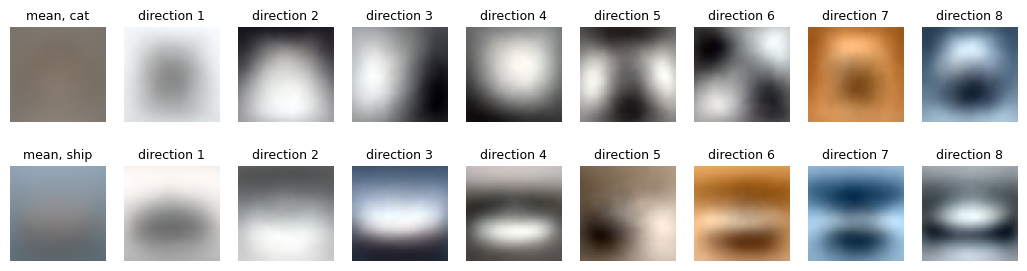

In [14]:
SHOW = [3, 8]   # cat and ship
FIGS = STORE / "figures"; FIGS.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 9, figsize=(13, 3.3))
for row, k in enumerate(SHOW):
    f = torch.load(FILTERS / f"class_{k}.pt", weights_only=False)
    axes[row, 0].imshow(as_image(f["mean_patch"].numpy()))
    axes[row, 0].set_title(f"mean, {CLASSES[k]}", fontsize=9)
    for j in range(8):
        axes[row, j + 1].imshow(as_direction(f["eigenvectors"][:, j].numpy()))
        axes[row, j + 1].set_title(f"direction {j + 1}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.savefig(FIGS / "pca_two_classes.png", dpi=200, bbox_inches="tight")
plt.show()

## Part B

In [15]:
N = 256
OUT = REPO / "results" / "part4"
SETTINGS = {
    "unguided": ("narfm", "--gaussian-strength 0 --rfm-strength 0"),
    "na_lam3":  ("na_only", 3.0),
    "na_lam8":  ("na_only", 8.0),
    "rfm_only": ("narfm", "--gaussian-strength 0 --rfm-sigma-lo 0 --rfm-sigma-hi 1000"),
    "na_rfm":   ("narfm", ""),
}
LABEL = {"unguided": "Unguided", "na_lam3": "Noise align. only (λ=3)", "na_lam8": "Noise align. only (λ=8)",
         "rfm_only": "RFM-only (all steps)", "na_rfm": "NA-RFM"}


def generate(name, n=N):
    script, arg = SETTINGS[name]
    out = OUT / name
    for k, c in enumerate(CLASSES):
        if (out / c / "samples.pt").exists():
            continue
        if script == "narfm":
            run(f"{sys.executable} repro/run_cifar10_na_rfm.py --classes {k} --num-samples {n} --seed-start 0 "
                f"--batch-size 64 --inference-steps 100 --eval-mode hf_convnext --output-dir {out} {arg}")
            continue
        raw = OUT / f"{name}_raw"
        pattern = f"{c}_mode=diff_str={arg}_seeds={n}_*.pt"
        if not list(raw.glob(pattern)):
            run(f"{sys.executable} repro/run_cifar10_na_only.py --class-idx {k} --mode diff --strength {arg} "
                f"--num-seeds {n} --inference-steps 100 --start-step 0 --end-step 50 --batch-size 64 "
                f"--eval-mode hf_convnext --output-dir {raw}")
        d = torch.load(next(raw.glob(pattern)), weights_only=False)
        (out / c).mkdir(parents=True, exist_ok=True)
        torch.save(d["samples"], out / c / "samples.pt")
        (out / c / "metrics.json").write_text(json.dumps(
            {"accuracy": float(d["accuracy"]), "correct": int((d["predictions"] == k).sum()),
             "total": int(len(d["predictions"]))}))


def measure(name):
    q = OUT / name / "quality.json"
    if not q.exists():
        run(f"{sys.executable} repro/evaluate_saved_samples.py --dataset cifar10 --samples-root {OUT / name} "
            f"--targets all --output {q} --batch-size 64")
    return json.loads(q.read_text())

In [16]:
for name in SETTINGS:
    print(f"\n===== {LABEL[name]} =====")
    generate(name)
    q = measure(name)
    print(f"{LABEL[name]}: accuracy {q['average_accuracy']:.1f}%, FID {q['average_fid']:.1f}")


===== Unguided =====
$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes 0 --num-samples 256 --seed-start 0 --batch-size 64 --inference-steps 100 --eval-mode hf_convnext --output-dir /content/na-rfm/results/part4/unguided --gaussian-strength 0 --rfm-strength 0
Loading CIFAR-10 diffusion model: data/checkpoints/openai_cifar10.pt

Sampling 0 (airplane)

airplane: 29/256 = 11.3%

Average accuracy: 11.3%
Results saved to: /content/na-rfm/results/part4/unguided
[180 s]
$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes 1 --num-samples 256 --seed-start 0 --batch-size 64 --inference-steps 100 --eval-mode hf_convnext --output-dir /content/na-rfm/results/part4/unguided --gaussian-strength 0 --rfm-strength 0
Loading CIFAR-10 diffusion model: data/checkpoints/openai_cifar10.pt

Sampling 1 (automobile)

automobile: 16/256 = 6.2%

Average accuracy: 6.2%
Results saved to: /content/na-rfm/results/part4/unguided
[190 s]
$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes 2 --num-sampl

## Part C

In [17]:
for name in SETTINGS:
    q = json.loads((OUT / name / "quality.json").read_text())
    print(f"{LABEL[name]:>26}: accuracy {q['average_accuracy']:5.1f}%,  FID {q['average_fid']:6.1f}")

                  Unguided: accuracy  10.0%,  FID  157.8
   Noise align. only (λ=3): accuracy  62.0%,  FID   91.0
   Noise align. only (λ=8): accuracy  79.8%,  FID  111.0
      RFM-only (all steps): accuracy  96.1%,  FID   95.3
                    NA-RFM: accuracy  96.0%,  FID   93.4


In [18]:
TIMES = STORE / "times.json"
times = {}
for name, (script, arg) in SETTINGS.items():
    times[name] = seconds_per_image(flags=arg) if script == "narfm" else seconds_per_image(na_only_strength=arg)
    print(f"{LABEL[name]:>26}: {times[name]:.3f} s per image")
TIMES.write_text(json.dumps(times, indent=2))

                  Unguided: 0.677 s per image
   Noise align. only (λ=3): 0.400 s per image
   Noise align. only (λ=8): 0.406 s per image
      RFM-only (all steps): 0.804 s per image
                    NA-RFM: 0.684 s per image


167

## Part d

In [19]:
PAPER = {
    "unguided": (None, None, None),
    "na_lam3":  (62.0, 99.0, 5.8),
    "na_lam8":  (80.0, 120.0, 5.8),
    "rfm_only": (94.8, 40.3, 6.8),
    "na_rfm":   (96.6, 41.4, 6.2),
}
rows = []
for name in SETTINGS:
    q = json.loads((OUT / name / "quality.json").read_text())
    pa, pf, pt = PAPER[name]
    rows.append({"Setting": LABEL[name],
                 "Acc. ours (%)": q["average_accuracy"], "Acc. paper (%)": pa,
                 "FID ours (256/class)": q["average_fid"], "FID paper (2048/class)": pf,
                 "Time ours (s/img, bs 64, T4)": times[name], "Time paper (s/16, A100)": pt})
table = pd.DataFrame(rows)
table.to_csv(STORE / "table2_replication.csv", index=False)
(STORE / "table2_replication.tex").write_text(table.to_latex(index=False, float_format="%.2f", na_rep="--"))

per_class = pd.DataFrame({(LABEL[n], m): {r["name"]: r[key] for r in json.loads((OUT / n / "quality.json").read_text())["classes"]}
                          for n in SETTINGS for m, key in [("acc", "accuracy"), ("FID", "fid")]})
per_class.to_csv(STORE / "per_class_acc_fid.csv")
display(table.round(2))
display(per_class.round(1))

,Setting,Acc. ours (%),Acc. paper (%),FID ours (256/class),FID paper (2048/class),"Time ours (s/img, bs 64, T4)","Time paper (s/16, A100)"
0,Unguided,10.00,NaN,157.76,NaN,0.68,NaN
1,Noise align. only (λ=3),61.99,62.0,91.01,99.0,0.40,5.8
2,Noise align. only (λ=8),79.80,80.0,111.02,120.0,0.41,5.8
3,RFM-only (all steps),96.09,94.8,95.29,40.3,0.80,6.8
4,NA-RFM,95.98,96.6,93.41,41.4,0.68,6.2


Unguided        Noise align. only (λ=3)         \
                acc    FID                     acc    FID   
airplane       11.3  158.6                    76.6   99.2   
automobile      6.2  172.0                    60.2   72.7   
bird            6.6  144.1                    40.6  110.5   
cat            17.6  143.7                    50.0  115.6   
deer            9.4  138.6                    60.9   98.2   
dog            11.7  153.1                    60.2  100.6   
frog           12.5  169.4                    72.3   94.8   
horse           6.6  157.6                    63.7   80.3   
ship           10.5  171.7                    77.3   64.8   
truck           7.4  168.7                    58.2   73.3   

           Noise align. only (λ=8)        RFM-only (all steps)        NA-RFM  \
                               acc    FID                  acc    FID    acc   
airplane                      96.5  131.1                 96.5  107.1  100.0   
automobile                    70.3   84.2                 99.6   64.2  100.0   
bird                          60.9  130.1                 93.0  115.6   94.5   
cat                           66.8  138.7                 99.2  119.4   99.6   
deer                          84.0  128.7                 92.6   99.9  100.0   
dog                           77.3  132.6                 99.2  100.2   96.5   
frog                          93.8  122.3                 96.9  111.2   99.6   
horse                         91.4   89.8                 99.2   86.5   97.7   
ship                          88.3   75.9                 93.4   79.5   85.5   
truck                         68.8   76.9                 91.4   69.3   86.3   

                   
              FID  
airplane     99.0  
automobile   66.2  
bird        118.1  
cat         110.2  
deer         97.9  
dog         106.4  
frog        101.8  
horse        84.8  
ship         75.5  
truck        74.1

In [20]:
def grid(name, per_class=16):
    rows = [torch.cat(list(torch.load(OUT / name / c / "samples.pt", weights_only=False)[:per_class].clamp(-1, 1)), dim=2)
            for c in CLASSES]
    return ((torch.cat(rows, dim=1) + 1) / 2).permute(1, 2, 0).numpy()

for name in SETTINGS:
    q = json.loads((OUT / name / "quality.json").read_text())
    fig, ax = plt.subplots(figsize=(8, 5.3))
    ax.imshow(grid(name), interpolation="nearest")
    ax.set_yticks(np.arange(10) * 32 + 16, CLASSES, fontsize=8)
    ax.set_xticks([])
    ax.set_title(f"{LABEL[name]}: accuracy {q['average_accuracy']:.1f}%, FID {q['average_fid']:.1f} (256/class)", fontsize=10)
    fig.savefig(FIGS / f"grid_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Comparison with the paper
What matches:
Accuracy matches Table 2 very well. Noise alignment gives 62.0% at λ = 3 and 79.8% at λ = 8. That is expected, as DDIM sampling with η = 0 is deterministic and we used the same seeds, checkpoint, and denoisers. RFM steering gives 96.1% for RFM only and 96.0% for NA-RFM, which is far above noise alignment alone. Raising λ from 3 to 8 trades image quality for accuracy and the λ = 8 samples are visibly oversaturated and less diverse.

What Doesn't Match:
- RFM accuracy: \
 The remaining gaps of about 2 points come from our refitted RFM directions which depend on the noise added to the features and on the random train/test split so our VRFM is not the paper's. NA-RFM's errors concentrate in ship (85.5%) and truck (86.3%).
- FID for the RFM settings: \
 Ours are 95.3 and 93.4 and Table 2 is 40.3 and 41.4. This is because we used 256 images per class rather than 2,048 and FID is biased upward for small samples. At this sample size the two settings are within noise of each other so their order differs from the paper's.
- FID for noise alignment alone: \
 Ours (91.0, 111.0) is lower than Table 2's (99, 120) despite the smaller sample. I don't really think this can be explained from the code but rather that the entries come from a different evaluation setup maybe.
- Time: \
 Noise alignment alone costs 0.40 s per image compared to 0.68–0.80 s for the RFM settings which run two network passes per step for CFG. The paper's times are closer together likely because a batch of 16 does not keep an A100 busy. Our unguided time (0.68 s) is inflated because it runs the RFM script with WRFM = 0 which still makes both CFG passes.